# P-1 ARX with Configurable Lag History + Telemanom Detection

This notebook evaluates an **autoregressive regression with exogenous predictors (ARX)** as a forecasting alternative to the LSTM model used by Hundman et al. for the NASA/JPL P-1 telemetry channel.

The lag order is controlled by one setting:

```python
AR_LAGS = 1
```

For a general lag order $p$, the model uses the previous $p$ telemetry observations and the previous $p$ observations of all 24 context/command variables:

$$
y_t
=
\beta_0
+
\sum_{k=1}^{p}\beta_k y_{t-k}
+
\sum_{k=1}^{p}\sum_{j=1}^{24}\gamma_{jk} z_{j,t-k}
+
\epsilon_t.
$$

With `AR_LAGS = 1`, the model has

$$
1(1+24)=25
$$

lagged predictors.

The forecasting model is trained only on the official P-1 training set. The labeled anomaly intervals are **not** used to fit the model.

After the telemetry forecasts are generated, they are passed to the same shared `detection.py` module used in the original P-1 comparison. The Telemanom-style error smoothing, dynamic thresholding, buffering, pruning, and event-level evaluation remain unchanged.

**Important:** `AR_LAGS` and Telemanom's `history_length` are different concepts.

- `AR_LAGS` controls how much temporal history is supplied to the ARX forecasting model.
- `history_length = 250` is retained for the P-1 forecast alignment and Telemanom detection procedure.


## 1. Import packages and locate the repository

This notebook is intended to be stored in the repository's `Models` folder.

The code below:

- imports the packages used for data handling, regression, validation, and plotting,
- finds the repository root,
- imports the shared `detection.py` module from the repository root.


In [43]:
# Standard libraries
import ast
import sys
from pathlib import Path

# Data and plotting
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

# Modeling and validation
from sklearn.linear_model import LinearRegression
from sklearn.model_selection import TimeSeriesSplit
from sklearn.metrics import mean_absolute_error

# ------------------------------------------------------------
# Locate the repository root.
# This works when the notebook is run from the repository root
# or from a folder one level below it, such as Models.
# ------------------------------------------------------------
repo_dir = Path.cwd().resolve()

if not (repo_dir / "detection.py").is_file():
    repo_dir = repo_dir.parent

if not (repo_dir / "detection.py").is_file():
    raise FileNotFoundError(
        "Could not find detection.py. Run this notebook from the "
        "fall-2026-spacecraft-sensors repository or its Models folder."
    )

# Allow Python to import detection.py from the repository root.
if str(repo_dir) not in sys.path:
    sys.path.insert(0, str(repo_dir))

import detection

print("Repository root:", repo_dir)
print("Detection module:", repo_dir / "detection.py")


Repository root: /Users/jezercahodaj/Desktop/Erdos-Project/fall-2026-spacecraft-sensors
Detection module: /Users/jezercahodaj/Desktop/Erdos-Project/fall-2026-spacecraft-sensors/detection.py


## 2. Load the P-1 training data, test data, and anomaly labels

The project repository stores the NASA/JPL data under `data/data`.

For P-1, each row contains 25 columns:

- column 0: the telemetry signal,
- columns 1–24: binary context/command features.

The training set is used to fit the forecasting model. The test set is used only after the model has been fitted.


In [44]:
# Path used by the project repository.
data_dir = repo_dir / "data" / "data"

# Load the official P-1 train and test arrays.
p1_train = np.load(data_dir / "train" / "P-1.npy")
p1_test = np.load(data_dir / "test" / "P-1.npy")

# Load the labeled anomaly intervals.
labels = pd.read_csv(data_dir / "labeled_anomalies.csv")

print("Training shape:", p1_train.shape)
print("Test shape:", p1_test.shape)
print("Number of telemetry columns:", 1)
print("Number of context columns:", p1_train.shape[1] - 1)


Training shape: (2872, 25)
Test shape: (8505, 25)
Number of telemetry columns: 1
Number of context columns: 24


## 3. Separate telemetry from the context features

The first column is the telemetry value we want to forecast.

The remaining 24 columns are treated as context/command indicators. From the earlier P-1 context exploration, the varying context features take values 0 and 1.

The individual physical meanings of these encoded context columns are not known, so they are given generic names such as `context_1`, `context_2`, and so on.


In [45]:
# Telemetry signal.
train_signal = p1_train[:, 0]
test_signal = p1_test[:, 0]

# Context/command features.
train_context = p1_train[:, 1:]
test_context = p1_test[:, 1:]

# Generic feature names.
context_names = [
    f"context_{i}"
    for i in range(1, train_context.shape[1] + 1)
]

print("Training telemetry observations:", len(train_signal))
print("Test telemetry observations:", len(test_signal))
print("Context features:", len(context_names))


Training telemetry observations: 2872
Test telemetry observations: 8505
Context features: 24


## 4. Use all 24 context features

All 24 P-1 context/command variables are retained.

For each lag $k=1,\ldots,p$, the forecasting model uses:

- telemetry $y_{t-k}$,
- all 24 context/command values $\mathbf z_{t-k}$.

No context feature selection is performed.

Some context variables are constant in the training set and some may contain redundant information. With multiple lags, this can create substantial multicollinearity. The model is being used for **forecasting**, so individual coefficients should not be interpreted causally.

The anomaly labels are not used at this stage.


In [46]:
# Use all 24 context features.
selected_context_names = context_names

# Their positions in the full 25-column data arrays are columns 1 through 24.
# Column 0 is the telemetry signal.
selected_data_columns = np.arange(1, p1_train.shape[1])

print("Context features used:", len(selected_context_names))
print()
print("Features:")
print(selected_context_names)


Context features used: 24

Features:
['context_1', 'context_2', 'context_3', 'context_4', 'context_5', 'context_6', 'context_7', 'context_8', 'context_9', 'context_10', 'context_11', 'context_12', 'context_13', 'context_14', 'context_15', 'context_16', 'context_17', 'context_18', 'context_19', 'context_20', 'context_21', 'context_22', 'context_23', 'context_24']


## 5. Construct the ARX($p$) training data

The number of lags is controlled by:

```python
AR_LAGS = 1
```

For every training target $y_t$, the predictor vector contains the previous $p$ complete P-1 observations:

$$
X_t =
[
y_{t-1},\mathbf z_{t-1},
y_{t-2},\mathbf z_{t-2},
\ldots,
y_{t-p},\mathbf z_{t-p}
].
$$

The response remains

$$
Y_t = y_t.
$$

The fitted model is

$$
y_t
=
\beta_0
+
\sum_{k=1}^{p}\beta_k y_{t-k}
+
\sum_{k=1}^{p}\sum_{j=1}^{24}\gamma_{jk} z_{j,t-k}
+
\epsilon_t.
$$

The first $p$ training observations cannot be used as responses because they do not have a complete $p$-lag history inside the training array.

No anomaly labels are used to construct these training data.


In [47]:
# ------------------------------------------------------------
# Choose the ARX lag order here.
# Change this one value to try another history length.
# Examples: 5, 10, 20, 30
# ------------------------------------------------------------
AR_LAGS = 1

def make_lagged_matrix(data, target_indices, n_lags):
    """Construct ARX predictors for selected target indices.

    For each target time t, predictors are the complete P-1 rows
    from t-1, t-2, ..., t-n_lags.

    Column 0 is telemetry.
    Columns 1: are the 24 context/command variables.
    """
    target_indices = np.asarray(target_indices)

    if len(target_indices) == 0:
        raise ValueError("target_indices must not be empty.")

    if np.min(target_indices) < n_lags:
        raise ValueError(
            "Every target index must be at least n_lags."
        )

    lag_blocks = []
    predictor_names = []

    for lag in range(1, n_lags + 1):
        lag_blocks.append(
            data[target_indices - lag, :]
        )

        predictor_names.append(
            f"telemetry_lag{lag}"
        )

        predictor_names.extend([
            f"{name}_lag{lag}"
            for name in context_names
        ])

    X = np.hstack(lag_blocks)

    return X, predictor_names


# Training responses begin at index AR_LAGS so that every
# target has a complete lag history.
train_target_indices = np.arange(
    AR_LAGS,
    len(p1_train)
)

X_train, predictor_names = make_lagged_matrix(
    p1_train,
    train_target_indices,
    AR_LAGS
)

y_train = p1_train[
    train_target_indices,
    0
]

print("ARX lag order:", AR_LAGS)
print("Training predictor matrix shape:", X_train.shape)
print("Training response shape:", y_train.shape)
print("Number of predictors:", X_train.shape[1])

assert X_train.shape[1] == AR_LAGS * p1_train.shape[1]
assert X_train.shape[0] == len(y_train)


ARX lag order: 1
Training predictor matrix shape: (2871, 25)
Training response shape: (2871,)
Number of predictors: 25


## 6. Time-series cross-validation

Before fitting the final ARX model, forecasting performance is evaluated within the official training set using `TimeSeriesSplit`.

Unlike ordinary random cross-validation, time-series cross-validation preserves temporal order. Each validation block occurs after the observations used to fit that fold.

For each fold, forecasting accuracy is summarized by mean absolute error:

$$
MAE
=
\frac{1}{n}
\sum_{i=1}^{n}
|y_i-\hat y_i|.
$$

A smaller MAE means the forecasts are closer to the observed telemetry values.

Because the predictors contain observed lagged values, this is a **one-step-ahead forecasting evaluation with observed history available at each time point**.

The anomaly labels are still not used.


In [48]:
# Five expanding-window validation splits.
tscv = TimeSeriesSplit(n_splits=5)

cv_rows = []

for fold, (fit_idx, val_idx) in enumerate(
    tscv.split(X_train),
    start=1
):
    # Fit the ARX regression using only observations before
    # the validation block.
    model_cv = LinearRegression()
    model_cv.fit(
        X_train[fit_idx],
        y_train[fit_idx]
    )

    # Forecast the later validation observations.
    val_predictions = model_cv.predict(
        X_train[val_idx]
    )

    # Store validation MAE for this fold.
    fold_mae = mean_absolute_error(
        y_train[val_idx],
        val_predictions
    )

    cv_rows.append({
        "fold": fold,
        "training_observations": len(fit_idx),
        "validation_observations": len(val_idx),
        "validation_MAE": fold_mae
    })

cv_results = pd.DataFrame(cv_rows)

display(cv_results)

print(
    "Mean validation MAE:",
    cv_results["validation_MAE"].mean()
)
print(
    "SD of validation MAE:",
    cv_results["validation_MAE"].std()
)


,fold,training_observations,validation_observations,validation_MAE
0,1,481,478,0.138728
1,2,959,478,0.130635
2,3,1437,478,0.129446
3,4,1915,478,0.117117
4,5,2393,478,0.146789


Mean validation MAE: 0.13254292960651112
SD of validation MAE: 0.011095075211257719


## 7. Fit the final ARX($p$) model

After the time-series validation check, the final ARX model is fitted using all available lagged P-1 training observations.

For the selected lag order $p$, `LinearRegression` estimates

$$
\hat y_t
=
\hat\beta_0
+
\sum_{k=1}^{p}\hat\beta_k y_{t-k}
+
\sum_{k=1}^{p}\sum_{j=1}^{24}
\hat\gamma_{jk}z_{j,t-k}.
$$

The model predicts telemetry values. It does **not** directly predict whether an observation is anomalous.


In [49]:
# Fit the final ARX(p) model using all available lagged training rows.
arx_model = LinearRegression()
arx_model.fit(X_train, y_train)

print(f"ARX({AR_LAGS}) model fitted.")
print("Intercept:", arx_model.intercept_)
print("Number of fitted coefficients:", len(arx_model.coef_))


ARX(1) model fitted.
Intercept: -0.11681255675780972
Number of fitted coefficients: 25


## 8. Inspect the fitted coefficients

The table below shows the fitted coefficients for all lagged telemetry and context predictors.

With multiple lags, there may be strong correlation among predictors, especially between nearby telemetry lags and repeated context histories. Therefore:

- coefficient estimates may be unstable,
- coefficients should **not** be interpreted causally,
- the primary purpose of this model is forecasting.

The most useful quantities for the project are the forecasting errors and the downstream anomaly-detection results.


In [50]:
# Create a coefficient table.
coefficient_table = pd.DataFrame({
    "predictor": predictor_names,
    "coefficient": arx_model.coef_
})

coefficient_table["absolute_coefficient"] = (
    coefficient_table["coefficient"].abs()
)

# Show the strongest fitted coefficients first.
coefficient_table = coefficient_table.sort_values(
    "absolute_coefficient",
    ascending=False
).reset_index(drop=True)

display(coefficient_table)


,predictor,coefficient,absolute_coefficient
0,telemetry_lag1,7.744464e-01,7.744464e-01
1,context_17_lag1,-6.776696e-01,6.776696e-01
2,context_18_lag1,5.510251e-01,5.510251e-01
3,context_19_lag1,2.723676e-01,2.723676e-01
4,context_6_lag1,1.932461e-01,1.932461e-01
5,context_11_lag1,-1.764856e-01,1.764856e-01
6,context_22_lag1,1.741457e-01,1.741457e-01
7,context_9_lag1,1.173866e-01,1.173866e-01
8,context_3_lag1,-1.136100e-01,1.136100e-01
9,context_7_lag1,1.076681e-01,1.076681e-01


## 9. Generate aligned P-1 test forecasts

The forecast range is kept identical to the authors' saved P-1 LSTM run and to the other project models:

- `history_length = 250`,
- first forecasted test index = 250,
- last forecasted test index = 8494,
- total forecasts = 8,245,
- `n_predictions = 10`.

For a target at time $t$, ARX($p$) uses

$$
[
y_{t-1},\mathbf z_{t-1},
\ldots,
y_{t-p},\mathbf z_{t-p}
].
$$

With the default `AR_LAGS = 1`, all 1 required prior observation(s) are available because the first forecast is not made until test index 250.

The value `history_length = 250` is retained for **Telemanom/P-1 alignment and detection**. It does not mean the ARX model itself uses 250 lags.


In [51]:
# Detection/alignment settings used for the authors' saved P-1 run.
HISTORY_LENGTH = 250
N_PREDICTIONS = 10

# The ARX lag history must fit inside the common forecast start.
if AR_LAGS > HISTORY_LENGTH:
    raise ValueError(
        "AR_LAGS cannot exceed HISTORY_LENGTH with the current "
        "common P-1 forecast alignment."
    )

# Match the number of forecasts in the saved P-1 LSTM run:
# 8505 - 250 - 10 = 8245 forecasts.
n_forecasts = (
    len(p1_test)
    - HISTORY_LENGTH
    - N_PREDICTIONS
)

# Original test indices being forecast:
# 250, 251, ..., 8494.
prediction_indices = np.arange(
    HISTORY_LENGTH,
    HISTORY_LENGTH + n_forecasts
)

# Build the same p-lag predictor structure used for training.
X_test, test_predictor_names = make_lagged_matrix(
    p1_test,
    prediction_indices,
    AR_LAGS
)

# Training and test predictor ordering must match exactly.
assert predictor_names == test_predictor_names

# Generate one forecast for every aligned test index.
arx_predictions = arx_model.predict(X_test)

# Actual telemetry values corresponding to those forecasts.
actual_aligned = p1_test[
    prediction_indices,
    0
]

arx_test_mae = mean_absolute_error(
    actual_aligned,
    arx_predictions
)

print("ARX lag order:", AR_LAGS)
print("Number of forecasts:", len(arx_predictions))
print("First forecasted test index:", prediction_indices[0])
print("Last forecasted test index:", prediction_indices[-1])
print("Aligned test MAE:", arx_test_mae)


ARX lag order: 1
Number of forecasts: 8245
First forecasted test index: 250
Last forecasted test index: 8494
Aligned test MAE: 0.12534669182497854


## 10. Plot actual and predicted telemetry

The plot below compares the ARX($p$) forecasts with the observed P-1 telemetry over the same aligned test period used for the LSTM and Random Forest comparisons.

This plot evaluates forecasting behavior only. The anomaly labels are not needed to create the forecasts.


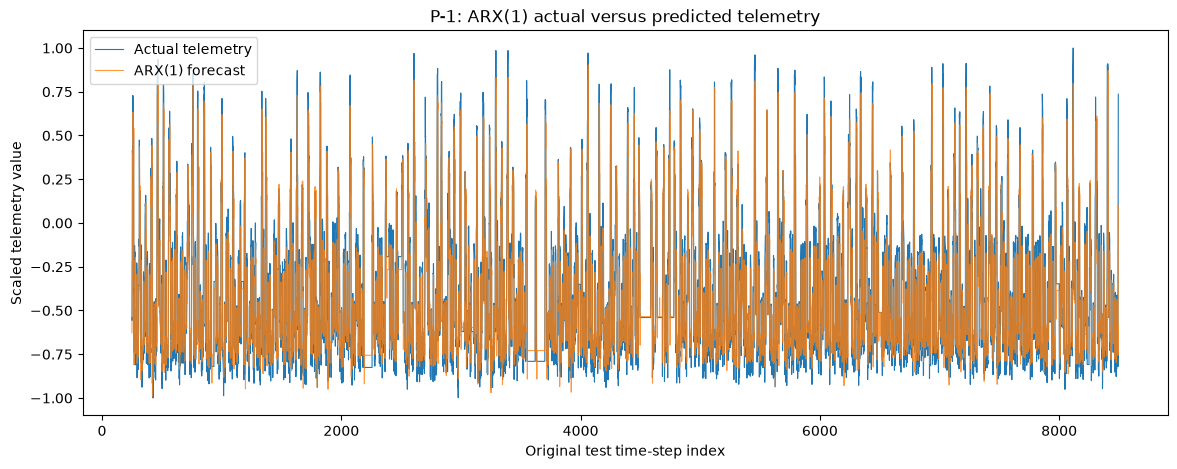

In [52]:
fig, ax = plt.subplots(figsize=(14, 5))

ax.plot(
    prediction_indices,
    actual_aligned,
    linewidth=0.8,
    label="Actual telemetry"
)

ax.plot(
    prediction_indices,
    arx_predictions,
    linewidth=0.8,
    alpha=0.8,
    label=f"ARX({AR_LAGS}) forecast"
)

ax.set(
    title=f"P-1: ARX({AR_LAGS}) actual versus predicted telemetry",
    xlabel="Original test time-step index",
    ylabel="Scaled telemetry value"
)

ax.legend()
plt.show()


## 11. Apply the shared Telemanom detection procedure

The ARX model produces telemetry forecasts, but it does not directly generate anomaly labels.

The forecasts are passed to the same shared `detection.py` module used in the other project analyses. The module:

1. computes absolute telemetry prediction errors,
2. smooths the errors using an exponentially weighted moving average,
3. selects dynamic thresholds within moving windows,
4. identifies and buffers candidate anomaly regions,
5. prunes weaker candidate intervals,
6. merges retained detections into final alert intervals.

The P-1 detector settings remain fixed:

- `history_length = 250`,
- `n_predictions = 10`,
- `batch_size = 70`,
- `window_size = 30`,
- `smoothing_perc = 0.05`,
- `error_buffer = 100`,
- `p = 0.13`,
- `initial_adjustment = True`,
- `initial_ignore = 500`.

Thus, changing `AR_LAGS` changes the **forecasting model's temporal history**, while the Telemanom detection procedure remains unchanged.


In [53]:
# Run the shared Telemanom-style detection procedure
# using the ARX forecasts instead of the saved LSTM forecasts.
arx_detection = detection.detect_anomalies(
    test_data=p1_test,
    predictions=arx_predictions,
    history_length=HISTORY_LENGTH,
    n_predictions=N_PREDICTIONS,
    target_column=0,
    batch_size=70,
    window_size=30,
    smoothing_perc=0.05,
    error_buffer=100,
    p=0.13,
    initial_adjustment=True,
    initial_ignore=500
)

print(f"Detected ARX({AR_LAGS}) alert intervals:")
print(arx_detection["detected_intervals"])
print()
print(
    "Number of detected intervals:",
    len(arx_detection["detected_intervals"])
)


Detected ARX(1) alert intervals:
[(4520, 4729)]

Number of detected intervals: 1


## 12. Examine the raw and smoothed forecast errors

For each aligned observation, the raw prediction error is

$$
e_t
=
\left|y_t-\hat{y}_t\right|.
$$

The Telemanom detection procedure then smooths these errors with an exponentially weighted moving average.

The smoothed errors, rather than the raw errors alone, are used in the dynamic thresholding procedure.


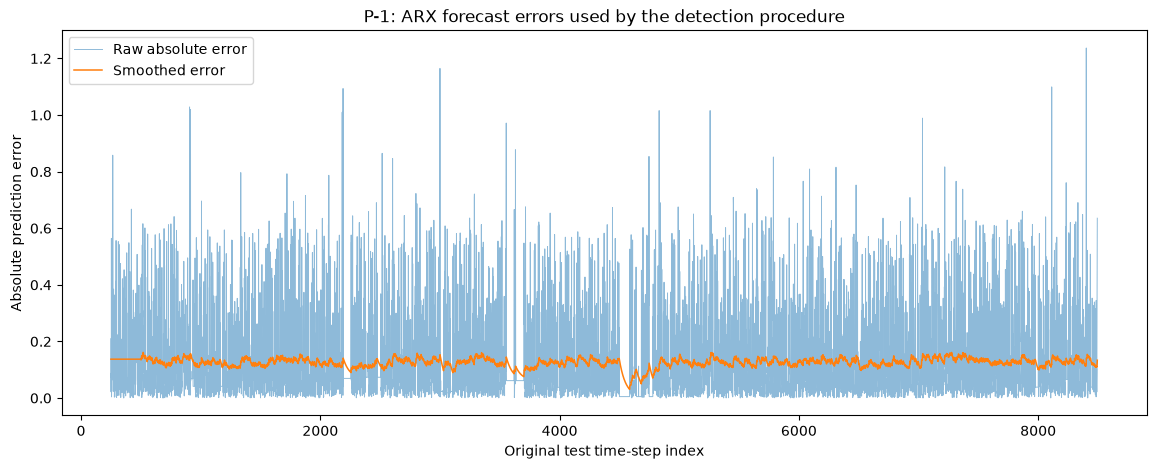

In [54]:
error_indices = arx_detection["prediction_indices"]

fig, ax = plt.subplots(figsize=(14, 5))

ax.plot(
    error_indices,
    arx_detection["raw_errors"],
    linewidth=0.7,
    alpha=0.5,
    label="Raw absolute error"
)

ax.plot(
    error_indices,
    arx_detection["smoothed_errors"],
    linewidth=1.1,
    label="Smoothed error"
)

ax.set(
    title="P-1: ARX forecast errors used by the detection procedure",
    xlabel="Original test time-step index",
    ylabel="Absolute prediction error"
)

ax.legend()
plt.show()


## 13. Load the labeled P-1 anomaly events

The labeled anomaly intervals are introduced **only after** model fitting and anomaly-alert generation.

The CSV stores the intervals as text, so `ast.literal_eval` converts them into Python lists of inclusive `(start, end)` pairs.

For the event-level evaluation used here, an event is considered detected if at least one detected alert interval overlaps it.


In [55]:
# Select all rows associated with P-1.
p1_label_rows = labels.loc[
    labels["chan_id"] == "P-1"
]

if p1_label_rows.empty:
    raise ValueError("No anomaly labels found for P-1.")

# Convert the text representation of the anomaly sequences
# into inclusive (start, end) intervals.
# The set removes exact duplicates if multiple rows contain
# the same interval.
labeled_intervals = sorted({
    (int(start), int(end))
    for sequences in p1_label_rows["anomaly_sequences"]
    for start, end in ast.literal_eval(sequences)
})

print("Labeled P-1 events:")
print(labeled_intervals)

print()
print(
    "Anomaly class information:",
    p1_label_rows["class"].tolist()
)


Labeled P-1 events:
[(2149, 2349), (3539, 3779), (4536, 4844)]

Anomaly class information: ['[contextual, contextual, contextual]']


## 14. Event-level anomaly detection evaluation

The shared evaluation function reports:

- **TP**: labeled events overlapped by at least one detected alert,
- **FP**: detected alert intervals that overlap no labeled event,
- **FN**: labeled events that overlap no detected alert.

Event precision is

$$
\text{Precision}
=
\frac{TP}{TP+FP}.
$$

Event recall is

$$
\text{Recall}
=
\frac{TP}{TP+FN}.
$$

The F1 score is

$$
F_1
=
2
\frac{\text{Precision}\times\text{Recall}}
{\text{Precision}+\text{Recall}}.
$$

The original Telemanom paper also emphasized $F_{0.5}$, which gives precision more weight than recall:

$$
F_{0.5}
=
(1+0.5^2)
\frac{\text{Precision}\times\text{Recall}}
{0.5^2\text{Precision}+\text{Recall}}.
$$

These are **event-overlap metrics**. They do not measure how closely the predicted alert boundaries match the full labeled interval.


In [56]:
# Compare detected ARX alert intervals with the labeled events.
evaluation = detection.evaluate_event_detection(
    detected_intervals=arx_detection["detected_intervals"],
    labeled_intervals=labeled_intervals
)

precision = evaluation["precision"]
recall = evaluation["recall"]

# Compute F_0.5 to accompany Diego's F1 output.
beta = 0.5

if np.isnan(precision) or np.isnan(recall):
    f_beta = np.nan
elif beta**2 * precision + recall == 0:
    f_beta = np.nan
else:
    f_beta = (
        (1 + beta**2)
        * precision
        * recall
        / (beta**2 * precision + recall)
    )

print(f"ARX({AR_LAGS}) + context + Telemanom detection")
print("-----------------------------------------")
print(f"TP: {evaluation['TP']}")
print(f"FP: {evaluation['FP']}")
print(f"FN: {evaluation['FN']}")
print(f"Precision: {precision:.1%}")
print(f"Recall: {recall:.1%}")
print(f"F1: {evaluation['f1']:.3f}")
print(f"F0.5: {f_beta:.3f}")


ARX(1) + context + Telemanom detection
-----------------------------------------
TP: 1
FP: 0
FN: 2
Precision: 100.0%
Recall: 33.3%
F1: 0.500
F0.5: 0.714


## 15. Check which labeled events were detected

This table reports whether each labeled P-1 event overlaps at least one ARX-based alert.

It is useful because event-level recall alone does not show which particular anomaly was missed.


In [57]:
event_table = pd.DataFrame({
    "labeled_interval": labeled_intervals,
    "detected": evaluation["detected_event_mask"]
})

display(event_table)


,labeled_interval,detected
0,"(2149, 2349)",False
1,"(3539, 3779)",False
2,"(4536, 4844)",True


## 16. Plot labeled events and ARX-based detected alerts

The final plot compares:

- observed P-1 telemetry,
- labeled anomaly-event intervals,
- alert intervals produced from the ARX($p$) forecast errors by `detection.py`.

An overlap means the labeled event was detected under the event-level evaluation.

The alert does not need to cover the entire labeled interval to count as an event detection.


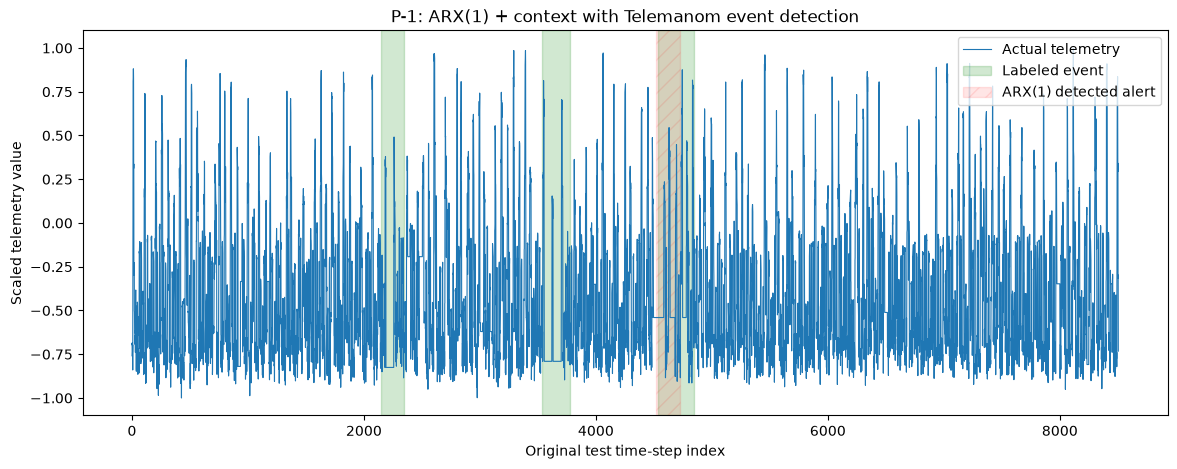

In [58]:
fig, ax = plt.subplots(figsize=(14, 5))

# Plot the P-1 telemetry.
ax.plot(
    np.arange(len(p1_test)),
    p1_test[:, 0],
    linewidth=0.8,
    label="Actual telemetry"
)

# Shade labeled anomaly events.
for i, (start, end) in enumerate(labeled_intervals):
    ax.axvspan(
        start,
        end,
        color = "green",
        alpha=0.18,
        label="Labeled event" if i == 0 else None
    )

# Shade detected alert intervals with a hatch pattern.
for i, (start, end) in enumerate(
    arx_detection["detected_intervals"]
):
    ax.axvspan(
        start,
        end,
        color = "red",
        alpha=0.10,
        hatch="//",
        label=f"ARX({AR_LAGS}) detected alert" if i == 0 else None
    )

ax.set(
    title=f"P-1: ARX({AR_LAGS}) + context with Telemanom event detection",
    xlabel="Original test time-step index",
    ylabel="Scaled telemetry value"
)

ax.legend()
plt.show()


## 17. Detection-window diagnostics

The Telemanom procedure evaluates prediction errors within moving windows.

For each window, `detection.py` records:

- whether the high-error or inverted-error branch was analyzed,
- the selected $z$ multiplier,
- the resulting threshold,
- the number of readings retained after candidate detection and pruning.

These diagnostics help explain why particular alert intervals were produced.


In [59]:
# Display the first several detection-window results.
display(
    arx_detection["window_results"].head(20)
)

print(
    "Total detection-window rows:",
    len(arx_detection["window_results"])
)

# Show only detector windows/branches that retained readings.
active_windows = arx_detection["window_results"].loc[
    arx_detection["window_results"]["retained readings"] > 0
].copy()

print()
print("Windows/branches with retained readings:")
display(active_windows)


,window,branch,z,threshold,retained readings
0,0,high errors,2.5,0.158393,0
1,0,low errors,2.5,0.158393,0
2,1,high errors,2.5,0.158141,0
3,1,low errors,2.5,0.158141,0
4,2,high errors,2.5,0.157593,0
5,2,low errors,2.5,0.157593,0
6,3,high errors,2.5,0.157161,0
7,3,low errors,2.5,0.157161,0
8,4,high errors,2.5,0.156751,0
9,4,low errors,2.5,0.156751,0


Total detection-window rows: 176

Windows/branches with retained readings:


,window,branch,z,threshold,retained readings
65,32,low errors,2.5,0.172068,70
67,33,low errors,2.5,0.175315,70
69,34,low errors,2.5,0.177541,70


## 18. Interpretation and comparison

This notebook allows the amount of temporal history supplied to the ARX forecasting model to be 
changed while keeping the shared Telemanom-style detection procedure fixed.

The pipeline is

$$
\text{$p$ lags of telemetry + $p$ lags of all 24 context features}
\rightarrow
\text{ARX($p$) forecast}
\rightarrow
\text{telemetry prediction errors}
\rightarrow
\text{Telemanom detection}
\rightarrow
\text{event-level evaluation}.
$$

The main quantities to report are:

1. chosen `AR_LAGS`,
2. time-series cross-validation MAE,
3. aligned P-1 test MAE,
4. number and locations of detected alert intervals,
5. event-level TP, FP, and FN,
6. event-level precision, recall, F1, and $F_{0.5}$,
7. which Telemanom windows/branches retained readings.

### Comparison of lag orders

The ARX(1) model detected 1 of the 3 labeled P-1 events under the shared detector.

By changing only

- AR_LAGS = 1

you can test whether giving the linear forecasting model a longer temporal history produces more distinctive residual behavior during the labeled anomaly events.

Useful lag values to compare include:


- AR_LAGS = 5
- AR_LAGS = 10
- AR_LAGS = 20
- AR_LAGS = 30

### Limitation

Increasing the lag order also increases the number of linear predictors: $25p.$

For example:

- $p=5$: 125 predictors,
- $p=10$: 250 predictors,
- $p=20$: 500 predictors,
- $p=30$: 750 predictors.

Nearby telemetry lags and repeated context variables can be strongly correlated. Therefore, higher-order ARX models may have unstable individual coefficients even when their forecasts are usable.

The comparison should focus primarily on forecasting performance and anomaly-detection behavior, not causal interpretation of individual coefficients.


# Computational cost benchmark

This section estimates the operational computing cost of **ARX(1) + Telemanom detection** using the same benchmarking and cloud-cost assumptions used in `Rios_Forecasting_Cost_Comparison.ipynb`.

## Benchmark scope

The benchmark uses the same **8,245 aligned P-1 test targets** evaluated earlier in this notebook.

Three operations are timed separately:

1. **Forecast generation:** reconstruct the model inputs for the aligned P-1 targets and generate predictions.
2. **Detection only:** process the already-generated forecasts through the shared `detection.py` procedure.
3. **Complete pipeline:** generate forecasts and then run the shared detector.

The benchmark excludes:

- data loading,
- imports,
- plotting,
- evaluation against anomaly labels,
- cross-validation and model selection,
- final-model training.

These are batch-processing measurements rather than real-time alert latencies.

Each timed operation is warmed up first. `timeit.autorange()` chooses a suitable number of calls, and the measurement is repeated **7 times**. The notebook reports the median and the 25th/75th percentiles, matching Diego's benchmark procedure.


## Reusable ARX(1) forecast operation

The forecast-generation benchmark intentionally reconstructs the required lagged test inputs on every call so that feature construction is included in forecast-generation time.

A diagnostic check verifies that this operation reproduces the predictions already used earlier in the notebook.


In [60]:
def generate_arx_forecasts(
    test_data,
    target_indices,
    fitted_model,
    n_lags
):
    """Rebuild ARX inputs and generate forecasts for the aligned targets."""

    X_batch, batch_predictor_names = make_lagged_matrix(
        test_data,
        target_indices,
        n_lags
    )

    # Verify that benchmark-time feature ordering matches model training.
    assert predictor_names == batch_predictor_names

    return fitted_model.predict(X_batch)


# Confirm that the reusable benchmark operation reproduces
# the forecasts already used in the anomaly-detection analysis.
arx_benchmark_check = generate_arx_forecasts(
    p1_test,
    prediction_indices,
    arx_model,
    AR_LAGS
)

assert np.allclose(
    arx_benchmark_check,
    arx_predictions
)

print(
    "Benchmark forecast check passed:",
    np.allclose(arx_benchmark_check, arx_predictions)
)

Benchmark forecast check passed: True


## Runtime benchmark

All numerical-library operations are limited to one thread during timing so that the local benchmark is closer to the later **1-vCPU** Fargate cost assumption.

The interquartile range reflects repeated local timing variability. It is not a confidence interval for cloud runtime.


In [61]:
import timeit
from threadpoolctl import threadpool_limits

MODEL_NAME = f"ARX({AR_LAGS})"

# Keep the detector identical to the model-evaluation section.
benchmark_detection_settings = {
    "history_length": HISTORY_LENGTH,
    "n_predictions": N_PREDICTIONS,
    "target_column": 0,
    "batch_size": 70,
    "window_size": 30,
    "smoothing_perc": 0.05,
    "error_buffer": 100,
    "p": 0.13,
    "initial_adjustment": True,
    "initial_ignore": 500,
}


def forecast_operation():
    """Construct ARX inputs and generate all 8,245 P-1 forecasts."""
    return generate_arx_forecasts(
        p1_test,
        prediction_indices,
        arx_model,
        AR_LAGS
    )


def detection_operation():
    """Run detection using the forecasts already generated above."""
    return detection.detect_anomalies(
        test_data=p1_test,
        predictions=arx_predictions,
        **benchmark_detection_settings
    )


def complete_pipeline_operation():
    """Generate forecasts, then run the shared detector."""
    predictions = forecast_operation()

    return detection.detect_anomalies(
        test_data=p1_test,
        predictions=predictions,
        **benchmark_detection_settings
    )


benchmark_operations = {
    "Forecast generation": forecast_operation,
    "Detection only": detection_operation,
    "Complete pipeline": complete_pipeline_operation,
}

runtime_rows = []

# Match Diego's timing approach: use a one-thread numerical environment,
# warm up each operation, let timeit choose a suitable number of calls,
# then repeat the timing 7 times.
with threadpool_limits(limits=1):

    for stage, operation in benchmark_operations.items():

        # Warm-up call is excluded from the recorded measurements.
        operation()

        timer = timeit.Timer(operation)

        # Select enough calls for one timing measurement to last
        # approximately 0.2 seconds or longer.
        calls_per_repeat, _ = timer.autorange()

        elapsed = np.asarray(
            timer.repeat(
                repeat=7,
                number=calls_per_repeat
            )
        )

        milliseconds = (
            elapsed
            / calls_per_repeat
            * 1000
        )

        runtime_rows.append({
            "model": MODEL_NAME,
            "stage": stage,
            "calls per repeat": calls_per_repeat,
            "median ms": np.median(milliseconds),
            "25th percentile ms": np.percentile(milliseconds, 25),
            "75th percentile ms": np.percentile(milliseconds, 75),
        })

runtime_results = pd.DataFrame(runtime_rows)

display(runtime_results.round(4))

,model,stage,calls per repeat,median ms,25th percentile ms,75th percentile ms
0,ARX(1),Forecast generation,2000,0.1495,0.1490,0.1497
1,ARX(1),Detection only,5,53.8502,53.7866,53.9572
2,ARX(1),Complete pipeline,5,54.2233,54.2081,54.2585


## Illustrative AWS Fargate cost scenario

To keep the group comparison consistent, this section uses the same deployment assumptions as Diego's cost notebook.

The official AWS Fargate pricing page lists, under **Pricing Examples → Example 1**, Linux/x86 rates for US East (N. Virginia) of:

- **$0.000011244 per vCPU-second**
- **$0.000001235 per GB-second**

AWS states that Linux Fargate duration is billed per second with a **1-minute minimum**, rounded up to the nearest whole second.

### Assumptions

- allocate **1 vCPU and 2 GB memory**;
- process **1,000 P-1-sized batches per day**;
- each batch contains the same **8,245 evaluated targets**;
- use one task per day that processes the 1,000 batches sequentially;
- use **30 days per month**;
- add **30 seconds of startup/other overhead** per daily task;
- examine cloud runtimes equal to **0.5×, 1×, and 2×** the measured local complete-pipeline runtime;
- exclude training, model selection, storage, networking, logging, taxes, and human alert investigation.

This is an illustrative deployment scenario rather than a measured AWS deployment.

For measured complete-pipeline batch runtime $t_{\mathrm{batch}}$ in seconds and cloud-to-local runtime multiplier $s$,

$$
t_{\mathrm{daily}}
=
1000\,t_{\mathrm{batch}}\,s+30.
$$

The estimated monthly computing cost is

$$
C_{\mathrm{month}}
=
30
\times
\max\left(
60,
\left\lceil t_{\mathrm{daily}}\right\rceil
\right)
\times
\left(
r_{\mathrm{CPU}}
+
2r_{\mathrm{memory}}
\right).
$$

The maximum and ceiling implement the 60-second minimum billed duration and whole-second rounding.


In [62]:
# Published Fargate Linux/x86 Example 1 rates,
# US East (N. Virginia).
cpu_price_per_second = 0.000011244
memory_price_per_gb_second = 0.000001235

allocated_vcpus = 1
allocated_memory_gb = 2

batches_per_day = 1000
days_per_month = 30
startup_seconds_per_day = 30

runtime_multipliers = [
    0.5,
    1.0,
    2.0
]

allocated_price_per_second = (
    allocated_vcpus * cpu_price_per_second
    + allocated_memory_gb * memory_price_per_gb_second
)

# Use the measured median complete-pipeline runtime.
pipeline_median_ms = runtime_results.loc[
    runtime_results["stage"] == "Complete pipeline",
    "median ms"
].iloc[0]

pipeline_batch_seconds = (
    pipeline_median_ms / 1000
)

cost_rows = []

for multiplier in runtime_multipliers:

    processing_seconds = (
        batches_per_day
        * pipeline_batch_seconds
        * multiplier
    )

    daily_task_seconds = (
        processing_seconds
        + startup_seconds_per_day
    )

    billed_seconds_per_day = max(
        60,
        int(np.ceil(daily_task_seconds))
    )

    monthly_cost = (
        billed_seconds_per_day
        * days_per_month
        * allocated_price_per_second
    )

    cost_rows.append({
        "model": MODEL_NAME,
        "runtime multiplier": multiplier,
        "median local batch seconds": pipeline_batch_seconds,
        "processing seconds per day": processing_seconds,
        "billed seconds per day": billed_seconds_per_day,
        "estimated monthly USD": monthly_cost
    })

cost_estimates = pd.DataFrame(
    cost_rows
)

display(
    cost_estimates.round(4)
)

reference_cost = cost_estimates.loc[
    cost_estimates["runtime multiplier"] == 1.0,
    "estimated monthly USD"
].iloc[0]

print(
    f"{MODEL_NAME} estimated monthly cost at 1x local runtime:",
    f"${reference_cost:.4f}"
)

# For context, this is the cost of keeping the same allocation
# continuously active for 30 days.
always_running_monthly_cost = (
    days_per_month
    * 24
    * 3600
    * allocated_price_per_second
)

print(
    "Same 1-vCPU / 2-GB allocation running continuously for 30 days:",
    f"${always_running_monthly_cost:.2f}"
)


,model,runtime multiplier,median local batch seconds,processing seconds per day,billed seconds per day,estimated monthly USD
0,ARX(1),0.5,0.0542,27.1117,60,0.0247
1,ARX(1),1.0,0.0542,54.2233,85,0.0350
2,ARX(1),2.0,0.0542,108.4466,139,0.0572


ARX(1) estimated monthly cost at 1x local runtime: $0.0350
Same 1-vCPU / 2-GB allocation running continuously for 30 days: $35.55


## Cost interpretation

The cost estimate is driven by the measured **complete-pipeline** runtime, not forecast generation alone.

The `1×` row assumes the cloud runs the code at the same speed as the local benchmark. The `0.5×` and `2×` rows are sensitivity scenarios and are not confidence intervals or measured cloud performance.

These estimates should be compared with the corresponding rows from the other forecasting models because the workload, detector, resource allocation, billing rules, and deployment assumptions are intentionally held constant.


## Export results for three-model P-1 comparison
This optional cell saves forecasts, anomaly alerts, error traces and the measured cost benchmark for the dedicated comparison notebook. It does not change the fitted model.

In [63]:
# Export exactly the outputs needed by the separate comparison notebook.
# Run after the model, detector, and cost benchmark cells above.
comparison_dir = repo_dir / "results" / "hodaj_p1_model_comparison"
comparison_dir.mkdir(parents=True, exist_ok=True)

np.savez_compressed(
    comparison_dir / "arx_results.npz",
    indices=np.asarray(prediction_indices, dtype=int),
    predictions=np.asarray(arx_predictions, dtype=float).reshape(-1),
    detected_intervals=np.asarray(arx_detection["detected_intervals"], dtype=int).reshape(-1, 2),
    raw_errors=np.asarray(arx_detection["raw_errors"], dtype=float).reshape(-1),
    smoothed_errors=np.asarray(arx_detection["smoothed_errors"], dtype=float).reshape(-1),
)
runtime_results.to_csv(comparison_dir / "arx_runtime.csv", index=False)
cost_estimates.to_csv(comparison_dir / "arx_cost.csv", index=False)
print("Exported ARX comparison files to:", comparison_dir)

Exported ARX comparison files to: /Users/jezercahodaj/Desktop/Erdos-Project/fall-2026-spacecraft-sensors/results/hodaj_p1_model_comparison
